# Lab 3.3 · Kernel fusion and memory traffic

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

Separate elementwise kernels typically write an intermediate that the next kernel must read. A fused kernel can keep the intermediate local to the thread. For `ReLU(2x + 1)` with x = −2, the intermediate is −3 and the final value is zero. Fusing preserves the order of those operations.

Model two passes as one array read and one array write each. For one million FP32 elements, that is 16 MB of logical array traffic. A fused pass accounts for 8 MB. Real DRAM traffic depends on cache behavior and implementation. The experiment compares output parity and counts modeled bytes.

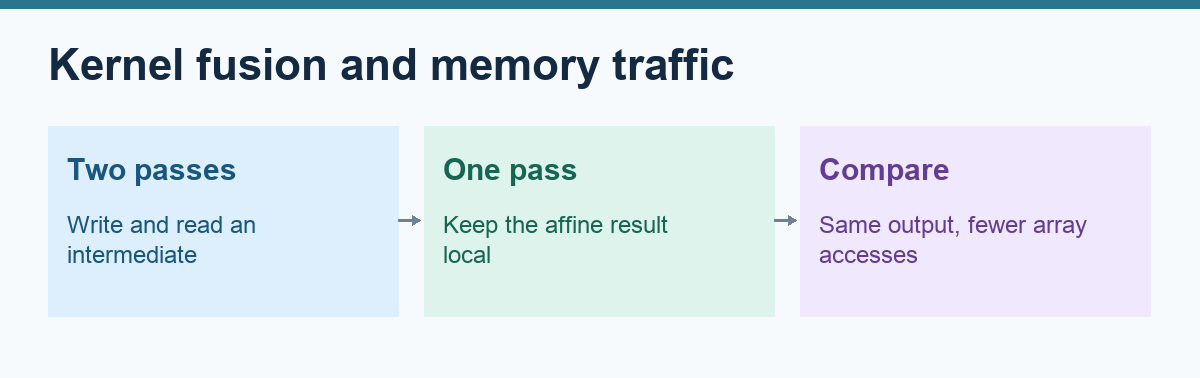

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Fuse the operation | Return ReLU(2x + 1) for each element in one pass. | The boundary case x = −0.5 tests the order of affine computation and activation. |
| 2. Count bytes | Return the logical bytes read and written across the requested number of passes. Include the final write. | The reduction comes from removing one write and one read of the intermediate. |

In [ ]:
values = [-2, -0.5, 0, 1, 3]

def separate(xs):
    intermediate = [2 * x + 1 for x in xs]
    return [max(0, value) for value in intermediate]

## Exercise 1. Fuse the operation

Return ReLU(2x + 1) for each element in one pass.

In [ ]:
def fused(xs):
    return None

In [ ]:
output = fused(values)
if output is None:
    print("Complete fused.")
else:
    assert output == separate(values) == [0, 0, 1, 3, 7]
    assert fused([]) == []
    print("PASS — fused result:", output)

### Read the result

The boundary case x = −0.5 tests the order of affine computation and activation.

## Exercise 2. Count bytes

Return the logical bytes read and written across the requested number of passes. Include the final write.

In [ ]:
def traffic(elements, bytes_per_value, passes):
    return None

In [ ]:
split_bytes = traffic(1_000_000, 4, 2)
if split_bytes is not None:
    fused_bytes = traffic(1_000_000, 4, 1)
    assert (split_bytes, fused_bytes) == (16_000_000, 8_000_000)
    assert traffic(3, 2, 1) == 12
    print("PASS — modeled split and fused bytes:", split_bytes, fused_bytes)

### Read the result

The reduction comes from removing one write and one read of the intermediate.

## Optional extension

Suppose another consumer also needs the affine output. Redo the byte budget when the fused operation must write that output as well. Explain why a profiler is needed to measure actual DRAM traffic.

## Reading

Philip Kiely, *Inference Engineering*, §4.1.3, pp. 100–101.

- [NVIDIA CUDA programming guide](https://docs.nvidia.com/cuda/cuda-programming-guide/02-basics/writing-cuda-kernels.html)